In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    auc,
)

In [2]:



def expected_calibration_error(y_true, y_prob, n_bins=10):

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n_total = len(y_true)

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        # include right edge on the last bin
        if i == n_bins - 1:
            in_bin = (y_prob >= lo) & (y_prob <= hi)
        else:
            in_bin = (y_prob >= lo) & (y_prob < hi)

        n_bin = in_bin.sum()
        if n_bin == 0:
            continue

        acc_bin        = y_true[in_bin].mean()
        confidence_bin = y_prob[in_bin].mean()
        ece           += (n_bin / n_total) * abs(acc_bin - confidence_bin)

    return ece


def evaluate_model(model, data_loader, device, threshold=0.5):

    model.eval()
    all_probs  = []
    all_labels = []

    with torch.no_grad():
        for batch in data_loader:
            # adjust unpacking if your loader yields a different structure
            if len(batch) == 3:
                X_ts_b, X_demo_b, y_b = batch
                X_ts_b   = X_ts_b.to(device)
                X_demo_b = X_demo_b.to(device)
                logits   = model(X_ts_b, X_demo_b)
            else:
                X_b, y_b = batch
                X_b      = X_b.to(device)
                logits   = model(X_b)

            probs = F.softmax(logits, dim=1)[:, 1]   # P(class=1)
            all_probs.append(probs.cpu().numpy())
            all_labels.append(y_b.numpy())

    y_prob = np.concatenate(all_probs)
    y_true = np.concatenate(all_labels)
    y_pred = (y_prob >= threshold).astype(int)

    # ── confusion matrix ───────────────────────────────────────────────────
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    # ── core classification metrics ───────────────────────────────────────
    accuracy          = accuracy_score(y_true, y_pred)
    balanced_accuracy  = balanced_accuracy_score(y_true, y_pred)
    sensitivity       = tp / (tp + fn) if (tp + fn) > 0 else 0.0   # recall / TPR
    specificity       = tn / (tn + fp) if (tn + fp) > 0 else 0.0   # TNR

    # ── probabilistic metrics ──────────────────────────────────────────────
    auroc = roc_auc_score(y_true, y_prob)
    auprc = average_precision_score(y_true, y_prob)

    # negative log-likelihood (log loss); clip probs to avoid log(0)
    y_prob_clipped = np.clip(y_prob, 1e-7, 1 - 1e-7)
    nll = log_loss(y_true, y_prob_clipped)

    # brier score: mean squared error between predicted prob and true label
    brier = brier_score_loss(y_true, y_prob)

    # expected calibration error
    ece = expected_calibration_error(y_true, y_prob, n_bins=10)

    # ── prevalence ──────────────────────────────────────────────────────────
    positive_prevalence = y_true.mean()

    metrics = {
        "accuracy":                 accuracy,
        "balanced_accuracy":        balanced_accuracy,
        "auroc":                    auroc,
        "auprc":                    auprc,
        "sensitivity":              sensitivity,
        "specificity":              specificity,
        "negative_log_likelihood":  nll,
        "brier_score":              brier,
        "expected_calibration_error": ece,
        "tn": float(tn),
        "fp": float(fp),
        "fn": float(fn),
        "tp": float(tp),
        "positive_prevalence":      positive_prevalence,
    }

    return metrics


def print_metrics(metrics: dict):
    """Pretty-print metrics dict matching the format you'd report/log."""
    print(f"accuracy {metrics['accuracy']:.6f}")
    print(f"balanced_accuracy {metrics['balanced_accuracy']:.6f}")
    print(f"auroc {metrics['auroc']:.6f}")
    print(f"auprc {metrics['auprc']:.6f}")
    print(f"sensitivity {metrics['sensitivity']:.6f}")
    print(f"specificity {metrics['specificity']:.6f}")
    print(f"negative_log_likelihood {metrics['negative_log_likelihood']:.6f}")
    print(f"brier_score {metrics['brier_score']:.6f}")
    print(f"expected_calibration_error {metrics['expected_calibration_error']:.6f}")
    print(f"tn {metrics['tn']:.6f}")
    print(f"fp {metrics['fp']:.6f}")
    print(f"fn {metrics['fn']:.6f}")
    print(f"tp {metrics['tp']:.6f}")
    print(f"positive_prevalence {metrics['positive_prevalence']:.6f}")


if __name__ == "__main__":
    pass

# metrics = evaluate_model(model, ts_test_loader, device)
# print_metrics(metrics)


In [3]:
def as_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def probs_to_predictions(probs, threshold=0.5):

    probs = as_numpy(probs)

    if probs.ndim == 1:
        return (probs >= threshold).astype(int)

    if probs.ndim == 2:
        return np.argmax(probs, axis=1).astype(int)

    raise ValueError("probs must have shape [N] or [N, C].")


def positive_class_probability(probs):

    probs = as_numpy(probs)

    if probs.ndim == 1:
        return probs

    if probs.ndim == 2 and probs.shape[1] == 2:
        return probs[:, 1]

    raise ValueError("For binary metrics, probs must have shape [N] or [N, 2].")

In [4]:
def compute_auroc(y_true, probs):
    y_true = as_numpy(y_true).astype(int)
    p1 = positive_class_probability(probs)

    if len(np.unique(y_true)) < 2:
        return np.nan

    return roc_auc_score(y_true, p1)


def plot_roc_curve(y_true, probs):
    y_true = as_numpy(y_true).astype(int)
    p1 = positive_class_probability(probs)

    fpr, tpr, thresholds = roc_curve(y_true, p1)
    score = roc_auc_score(y_true, p1)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUROC = {score:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate / sensitivity")
    plt.title("ROC curve")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [5]:
def compute_auprc(y_true, probs):
    y_true = as_numpy(y_true).astype(int)
    p1 = positive_class_probability(probs)

    if len(np.unique(y_true)) < 2:
        return np.nan

    return average_precision_score(y_true, p1)


def plot_precision_recall_curve(y_true, probs):
    y_true = as_numpy(y_true).astype(int)
    p1 = positive_class_probability(probs)

    precision, recall, thresholds = precision_recall_curve(y_true, p1)
    score = average_precision_score(y_true, p1)
    prevalence = np.mean(y_true == 1)

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"AUPRC = {score:.3f}")
    plt.hlines(prevalence, 0, 1, linestyle="--", label=f"Baseline = {prevalence:.3f}")
    plt.xlabel("Recall / sensitivity")
    plt.ylabel("Precision")
    plt.title("Precision-recall curve")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [6]:
with np.load("EF_MVN_prior0pt5_test_posterior_predictive.npz") as data:
    ytest1  = data['labels']
    ypred1  = np.round(data['posterior_mean_class1'])
    yprobs1 = data['posterior_class1_probs']
    

In [7]:
with np.load("LF_MVN_prior0pt5_test_posterior_predictive.npz") as data:
    ytest2  = data['labels']
    ypred2  = np.round(data['posterior_mean_class1'])
    yprobs2 = data['posterior_class1_probs']
    

In [8]:
with np.load("earlycnn_100k.npz") as data:
    ytest3  = data['ytest']
    ypred3  = data['y_pred']
    yprobs3 = data['probs']

In [9]:
with np.load("latecnn_100k.npz") as data:
    ytest4  = data['ytest']
    ypred4  = data['y_pred']
    yprobs4 = data['probs']

In [10]:
yprobs3

array([[0.2064006 , 0.79359937],
       [0.29677436, 0.7032256 ],
       [0.6991087 , 0.30089128],
       ...,
       [0.7093192 , 0.2906808 ],
       [0.7013526 , 0.29864737],
       [0.03624703, 0.963753  ]], shape=(5442, 2), dtype=float32)

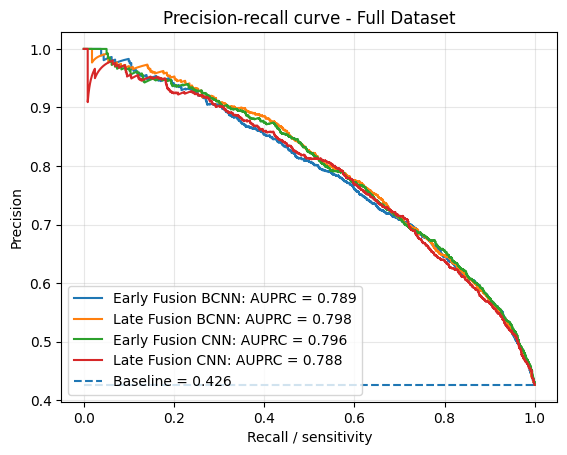

In [11]:

plt.figure()


y_true1 = as_numpy(ytest1).astype(int)
p1 = np.median(yprobs1,axis=0)#positive_class_probability(yprobs1)

y_true2 = ytest1#as_numpy(ytest2).astype(int)
p2 = np.median(yprobs2,axis=0)#positive_class_probability(yprobs2)

y_true3 = as_numpy(ytest3).astype(int)
p3 = positive_class_probability(yprobs3)

y_true4 = ytest4#as_numpy(ytest2).astype(int)
p4 = positive_class_probability(yprobs4)

precision1, recall1, thresholds1 = precision_recall_curve(y_true1, p1)
score1 = average_precision_score(y_true1, p1)

precision2, recall2, thresholds2 = precision_recall_curve(y_true2, p2)
score2 = average_precision_score(y_true2, p2)

precision3, recall3, thresholds3 = precision_recall_curve(y_true3, p3)
score3 = average_precision_score(y_true3, p3)

precision4, recall4, thresholds4 = precision_recall_curve(y_true4, p4)
score4 = average_precision_score(y_true4, p4)

prevalence = np.mean(y_true1 == 1)



plt.plot(recall1, precision1, label=f"Early Fusion BCNN: AUPRC = {score1:.3f}")
plt.plot(recall2, precision2, label=f"Late Fusion BCNN: AUPRC = {score2:.3f}")
plt.plot(recall3, precision3, label=f"Early Fusion CNN: AUPRC = {score3:.3f}")
plt.plot(recall4, precision4, label=f"Late Fusion CNN: AUPRC = {score4:.3f}")

plt.hlines(prevalence, 0, 1, linestyle="--", label=f"Baseline = {prevalence:.3f}")
plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")
plt.title("Precision-recall curve - Full Dataset")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

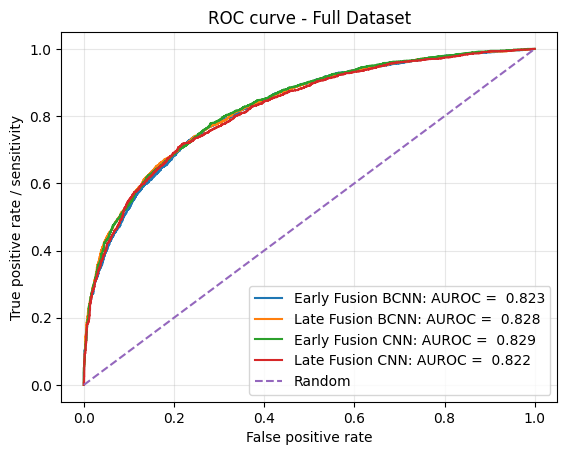

In [12]:


fpr1, tpr1, thresholds1 = roc_curve(y_true1, p1)
score1 = roc_auc_score(y_true1, p1)

fpr2, tpr2, thresholds2 = roc_curve(y_true2, p2)
score2 = roc_auc_score(y_true2, p2)

fpr3, tpr3, thresholds3 = roc_curve(y_true3, p3)
score3 = roc_auc_score(y_true3, p3)

fpr4, tpr4, thresholds4 = roc_curve(y_true4, p4)
score4 = roc_auc_score(y_true4, p4)

plt.figure()
plt.plot(fpr1, tpr1, label=f"Early Fusion BCNN: AUROC =  {score1:.3f}")
plt.plot(fpr2, tpr2, label=f"Late Fusion BCNN: AUROC =  {score2:.3f}")
plt.plot(fpr3, tpr3, label=f"Early Fusion CNN: AUROC =  {score3:.3f}")
plt.plot(fpr4, tpr4, label=f"Late Fusion CNN: AUROC =  {score4:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate / sensitivity")
plt.title("ROC curve - Full Dataset")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Bayesian sampling for uncertainty in ROC and PRC

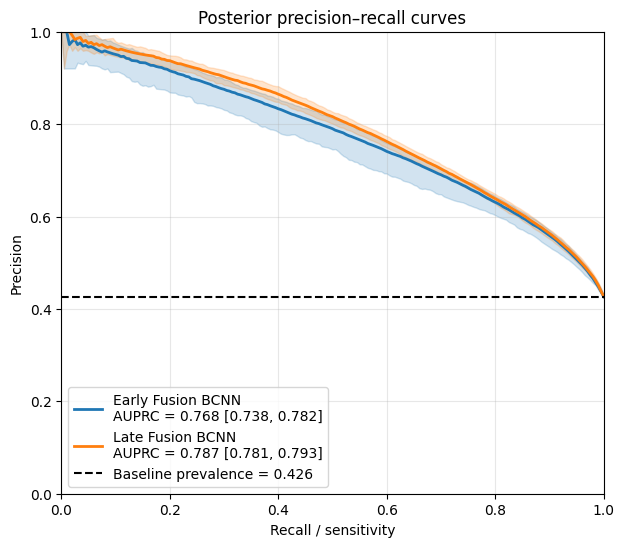

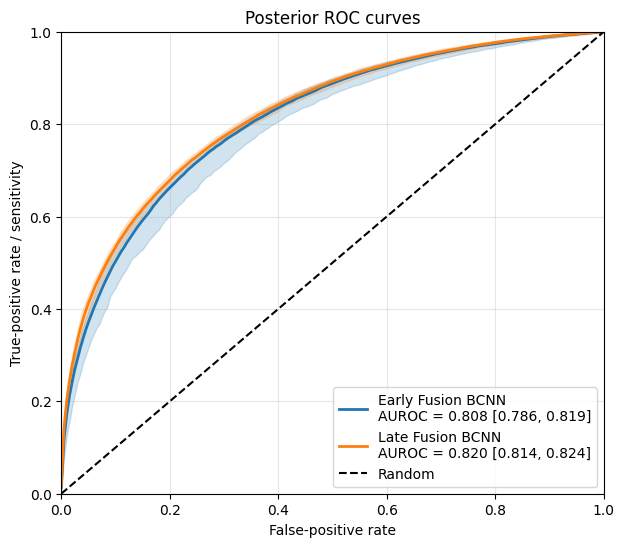

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
)

def interpolate_curve(x, y, x_grid):
    """Interpolate a curve onto a shared grid; safely handles duplicate x values."""
    x = np.asarray(x)
    y = np.asarray(y)

    order = np.argsort(x)
    x = x[order]
    y = y[order]

    x_unique, inverse = np.unique(x, return_inverse=True)

    # Keep the greatest y value when an x value appears more than once.
    y_unique = np.full(len(x_unique), -np.inf)
    np.maximum.at(y_unique, inverse, y)

    return np.interp(x_grid, x_unique, y_unique)


y_true = as_numpy(ytest1).astype(int)

models = {
    "Early Fusion BCNN": yprobs1,
    "Late Fusion BCNN": yprobs2,
}

prevalence = y_true.mean()
results = {}

fig_pr, ax_pr = plt.subplots(figsize=(7, 6))
fig_roc, ax_roc = plt.subplots(figsize=(7, 6))

fpr_grid = np.linspace(0, 1, 201)
recall_grid = np.linspace(0, 1, 201)

colors = {
    "Early Fusion BCNN": "C0",
    "Late Fusion BCNN": "C1",
}

for model_name, posterior_probs in models.items():
    posterior_probs = np.asarray(posterior_probs)

    # Supports (draws, patients) or (draws, patients, classes).
    if posterior_probs.ndim == 3:
        posterior_probs = posterior_probs[:, :, 1]

    aurocs = []
    auprcs = []
    tpr_per_draw = []
    precision_per_draw = []

    for draw_idx in range(posterior_probs.shape[0]):
        p_draw = posterior_probs[draw_idx]

        # ROC for this posterior draw.
        fpr, tpr, _ = roc_curve(y_true, p_draw)
        aurocs.append(roc_auc_score(y_true, p_draw))
        tpr_per_draw.append(interpolate_curve(fpr, tpr, fpr_grid))

        # PRC for this posterior draw.
        precision, recall, _ = precision_recall_curve(y_true, p_draw)
        auprcs.append(average_precision_score(y_true, p_draw))
        precision_per_draw.append(
            interpolate_curve(recall, precision, recall_grid)
        )

    aurocs = np.asarray(aurocs)
    auprcs = np.asarray(auprcs)
    tpr_per_draw = np.asarray(tpr_per_draw)
    precision_per_draw = np.asarray(precision_per_draw)

    color = colors[model_name]

    # Pointwise 95% credible band for ROC.
    roc_median = np.median(tpr_per_draw, axis=0)
    roc_lower = np.quantile(tpr_per_draw, 0.025, axis=0)
    roc_upper = np.quantile(tpr_per_draw, 0.975, axis=0)

    ax_roc.plot(
        fpr_grid,
        roc_median,
        color=color,
        linewidth=2,
        label=(
            f"{model_name}\n"
            f"AUROC = {aurocs.mean():.3f} "
            f"[{np.quantile(aurocs, 0.025):.3f}, "
            f"{np.quantile(aurocs, 0.975):.3f}]"
        ),
    )
    ax_roc.fill_between(
        fpr_grid,
        roc_lower,
        roc_upper,
        color=color,
        alpha=0.20,
        label="_nolegend_",
    )

    # Pointwise 95% credible band for PRC.
    pr_median = np.median(precision_per_draw, axis=0)
    pr_lower = np.quantile(precision_per_draw, 0.025, axis=0)
    pr_upper = np.quantile(precision_per_draw, 0.975, axis=0)

    ax_pr.plot(
        recall_grid,
        pr_median,
        color=color,
        linewidth=2,
        label=(
            f"{model_name}\n"
            f"AUPRC = {auprcs.mean():.3f} "
            f"[{np.quantile(auprcs, 0.025):.3f}, "
            f"{np.quantile(auprcs, 0.975):.3f}]"
        ),
    )
    ax_pr.fill_between(
        recall_grid,
        pr_lower,
        pr_upper,
        color=color,
        alpha=0.20,
        label="_nolegend_",
    )

    results[model_name] = {
        "AUROC_per_draw": aurocs,
        "AUPRC_per_draw": auprcs,
        "fpr_grid": fpr_grid,
        "roc_median": roc_median,
        "roc_lower_95": roc_lower,
        "roc_upper_95": roc_upper,
        "recall_grid": recall_grid,
        "pr_median": pr_median,
        "pr_lower_95": pr_lower,
        "pr_upper_95": pr_upper,
    }

# Final PRC formatting.
ax_pr.axhline(
    prevalence,
    color="black",
    linestyle="--",
    label=f"Baseline prevalence = {prevalence:.3f}",
)
ax_pr.set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="Recall / sensitivity",
    ylabel="Precision",
    title="Posterior precision–recall curves",
)
ax_pr.grid(alpha=0.3)
ax_pr.legend()

# Final ROC formatting.
ax_roc.plot([0, 1], [0, 1], "k--", label="Random")
ax_roc.set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="False-positive rate",
    ylabel="True-positive rate / sensitivity",
    title="Posterior ROC curves",
)
ax_roc.grid(alpha=0.3)
ax_roc.legend()

plt.show()

In [14]:
def confusion_counts(y_true, y_pred):
    y_true = as_numpy(y_true).astype(int)
    y_pred = as_numpy(y_pred).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn, fp, fn, tp

def compute_accuracy(y_true, y_pred):
    y_true = as_numpy(y_true)
    y_pred = as_numpy(y_pred)
    return np.mean(y_true == y_pred)

def compute_sensitivity_specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_counts(y_true, y_pred)

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    return sensitivity, specificity

def compute_balanced_accuracy(y_true, y_pred):
    sensitivity, specificity = compute_sensitivity_specificity(y_true, y_pred)
    return 0.5 * (sensitivity + specificity)

def compute_negative_log_likelihood(y_true, probs, eps=1e-12):
    y_true = as_numpy(y_true).astype(int)
    probs = as_numpy(probs)

    if probs.ndim == 1:
        p1 = np.clip(probs, eps, 1.0 - eps)
        return -np.mean(y_true * np.log(p1) + (1 - y_true) * np.log(1 - p1))

    if probs.ndim == 2:
        probs = np.clip(probs, eps, 1.0)
        probs = probs / probs.sum(axis=1, keepdims=True)
        return log_loss(y_true, probs, labels=[0, 1])

    raise ValueError("probs must have shape [N] or [N, 2].")

def compute_brier_score(y_true, probs):
    y_true = as_numpy(y_true).astype(int)
    p1 = positive_class_probability(probs)
    return np.mean((p1 - y_true) ** 2)

def compute_expected_calibration_error(y_true, probs, n_bins=10):
    """
    Confidence-based ECE for binary or multiclass probabilities.

    Args:
        y_true: shape [N]
        probs: shape [N, C] or shape [N] for binary P(class 1)
        n_bins: number of confidence bins

    Returns:
        ece: scalar
    """
    y_true = as_numpy(y_true).astype(int)
    probs = as_numpy(probs)

    if probs.ndim == 1:
        probs = np.column_stack([1.0 - probs, probs])

    y_pred = probs.argmax(axis=1)
    confidence = probs.max(axis=1)
    correct = (y_pred == y_true).astype(float)

    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0

    for m in range(n_bins):
        lo = bin_edges[m]
        hi = bin_edges[m + 1]

        if m == 0:
            in_bin = (confidence >= lo) & (confidence <= hi)
        else:
            in_bin = (confidence > lo) & (confidence <= hi)

        prop = np.mean(in_bin)

        if prop > 0:
            acc_bin = np.mean(correct[in_bin])
            conf_bin = np.mean(confidence[in_bin])
            ece += prop * abs(acc_bin - conf_bin)

    return ece


def calibration_table(y_true, probs, n_bins=10):
    """
    Return bin-level calibration information.
    """
    y_true = as_numpy(y_true).astype(int)
    probs = as_numpy(probs)

    if probs.ndim == 1:
        probs = np.column_stack([1.0 - probs, probs])

    y_pred = probs.argmax(axis=1)
    confidence = probs.max(axis=1)
    correct = (y_pred == y_true).astype(float)

    rows = []
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)

    for m in range(n_bins):
        lo = bin_edges[m]
        hi = bin_edges[m + 1]

        if m == 0:
            in_bin = (confidence >= lo) & (confidence <= hi)
        else:
            in_bin = (confidence > lo) & (confidence <= hi)

        n_bin = int(np.sum(in_bin))

        if n_bin > 0:
            rows.append({
                "bin": m + 1,
                "confidence_lower": lo,
                "confidence_upper": hi,
                "n": n_bin,
                "mean_confidence": float(np.mean(confidence[in_bin])),
                "empirical_accuracy": float(np.mean(correct[in_bin])),
                "abs_gap": float(abs(np.mean(correct[in_bin]) - np.mean(confidence[in_bin]))),
            })
        else:
            rows.append({
                "bin": m + 1,
                "confidence_lower": lo,
                "confidence_upper": hi,
                "n": 0,
                "mean_confidence": np.nan,
                "empirical_accuracy": np.nan,
                "abs_gap": np.nan,
            })

    return pd.DataFrame(rows)


def plot_calibration_curve(y_true, probs, n_bins=10):
    table = calibration_table(y_true, probs, n_bins=n_bins)
    table_nonempty = table.dropna(subset=["mean_confidence", "empirical_accuracy"])

    plt.figure(figsize=(6, 5))
    plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
    plt.scatter(
        table_nonempty["mean_confidence"],
        table_nonempty["empirical_accuracy"],
        s=50,
        label="Observed bins",
    )
    plt.xlabel("Mean confidence")
    plt.ylabel("Empirical accuracy")
    plt.title("Calibration curve")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

def estimate_negative_elbo_per_example_pyro(model, guide, data_loader, device, dataset_size=None):

    try:
        import pyro
        from pyro.infer import Trace_ELBO
    except ImportError as exc:
        raise ImportError("This function requires Pyro. Install pyro-ppl first.") from exc

    model.eval()
    elbo = Trace_ELBO()

    total_loss = 0.0
    total_examples = 0

    for x, y in data_loader:
        x = x.to(device)
        y = y.to(device)
        batch_size = x.shape[0]
        ds = dataset_size if dataset_size is not None else batch_size

        loss = elbo.differentiable_loss(model, guide, x, y, ds)

        total_loss += float(loss.detach().cpu())
        total_examples += batch_size

    return total_loss / max(total_examples, 1)


def estimate_cross_entropy_per_example_standard_nn(model, data_loader, device):
    """
    Estimate cross-entropy/NLL per example for a standard neural network.
    This is the standard deterministic analogue of the likelihood part of ELBO.
    """
    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for x, y in data_loader:
            x = x.to(device)
            y = y.to(device)
            logits = model(x)
            loss = F.cross_entropy(logits, y, reduction="sum")
            total_loss += float(loss.detach().cpu())
            total_examples += x.shape[0]

    return total_loss / max(total_examples, 1)

In [15]:
def calculate_binary_classification_metrics(y_true, probs, threshold=0.5, n_bins=10):
    """
    Calculate binary classification metrics from labels and probabilities.

    Args:
        y_true: shape [N], labels 0/1.
        probs: shape [N] containing P(class 1), or shape [N, 2].
        threshold: threshold for P(class 1), used only if probs has shape [N].
        n_bins: number of bins for ECE.

    Returns:
        metrics: dictionary
    """
    y_true = as_numpy(y_true).astype(int)
    probs = as_numpy(probs)

    if probs.ndim == 1:
        y_pred = probs_to_predictions(probs, threshold=threshold)
        p1 = probs
        probs_2d = np.column_stack([1.0 - p1, p1])
    else:
        y_pred = probs.argmax(axis=1)
        p1 = probs[:, 1]
        probs_2d = probs

    tn, fp, fn, tp = confusion_counts(y_true, y_pred)
    sensitivity, specificity = compute_sensitivity_specificity(y_true, y_pred)

    metrics = {
        "accuracy": compute_accuracy(y_true, y_pred),
        "balanced_accuracy": compute_balanced_accuracy(y_true, y_pred),
        "auroc": compute_auroc(y_true, probs_2d),
        "auprc": compute_auprc(y_true, probs_2d),
        "sensitivity": sensitivity,
        "specificity": specificity,
        "negative_log_likelihood": compute_negative_log_likelihood(y_true, probs_2d),
        "brier_score": compute_brier_score(y_true, probs_2d),
        "expected_calibration_error": compute_expected_calibration_error(y_true, probs_2d, n_bins=n_bins),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
        "positive_prevalence": float(np.mean(y_true == 1)),
    }

    return metrics

In [16]:
metrics_demo_early_CNN = calculate_binary_classification_metrics(
    y_true=y_true1,
    probs=p1,
    n_bins=10,
)
pd.DataFrame([metrics_demo_early_CNN]).T.rename(columns={0: "value"})

,value
accuracy,0.706725
balanced_accuracy,0.724691
auroc,0.823301
auprc,0.789440
sensitivity,0.845988
specificity,0.603393
negative_log_likelihood,0.568603
brier_score,0.193581
expected_calibration_error,0.015387
tn,1885.000000


In [17]:
metrics_demo_late_CNN = calculate_binary_classification_metrics(
    y_true=y_true2,
    probs=p2,
    n_bins=10,
)
pd.DataFrame([metrics_demo_late_CNN]).T.rename(columns={0: "value"})

,value
accuracy,0.751562
balanced_accuracy,0.744432
auroc,0.827625
auprc,0.798108
sensitivity,0.696290
specificity,0.792574
negative_log_likelihood,0.509833
brier_score,0.168698
expected_calibration_error,0.031301
tn,2476.000000


In [18]:
y_true = as_numpy(ytest1).astype(int)

models = {
    "Early Fusion BCNN": yprobs1,
    "Late Fusion BCNN": yprobs2,
}

posterior_metric_draws = {}
posterior_metric_summary = {}

for model_name, posterior_probs in models.items():
    posterior_probs = np.asarray(posterior_probs)

    # Supports either (draws, patients) or (draws, patients, classes).
    if posterior_probs.ndim == 3:
        posterior_probs = posterior_probs[:, :, 1]  # P(SHD)

    draw_metrics = []

    for draw_idx, p_draw in enumerate(posterior_probs):
        metrics = calculate_binary_classification_metrics(
            y_true=y_true,
            probs=p_draw,
            n_bins=10,
        )

        # Keep posterior-draw identity with each metric set.
        metrics["posterior_draw"] = draw_idx
        draw_metrics.append(metrics)

    # One row per posterior draw; one column per metric.
    metrics_df = pd.DataFrame(draw_metrics).set_index("posterior_draw")
    posterior_metric_draws[model_name] = metrics_df

    # Mean, SD, and central 95% posterior interval for each metric.
    posterior_metric_summary[model_name] = pd.DataFrame({
        "posterior_mean": metrics_df.mean(),
        "posterior_median": metrics_df.median(),
        "posterior_sd": metrics_df.std(ddof=1),
        "lower_95": metrics_df.quantile(0.025),
        "upper_95": metrics_df.quantile(0.975),
    })

# Example: all 200 early-fusion metric values
EF_draw_metrics = posterior_metric_draws["Early Fusion BCNN"]
LF_draw_metrics = posterior_metric_draws["Late Fusion BCNN"]

# Example: report the early-fusion metric posterior summary
display(posterior_metric_summary["Early Fusion BCNN"])
display(posterior_metric_summary["Late Fusion BCNN"])

,posterior_mean,posterior_median,posterior_sd,lower_95,upper_95
accuracy,0.672569,0.698456,7.513343e-02,0.475096,0.747887
balanced_accuracy,0.690435,0.711214,5.290089e-02,0.541634,0.740261
auroc,0.808211,0.810668,8.878184e-03,0.785911,0.819434
auprc,0.767906,0.770801,1.147515e-02,0.738156,0.781912
sensitivity,0.811066,0.830457,1.313229e-01,0.520664,0.990940
specificity,0.569805,0.606274,2.167911e-01,0.092382,0.890213
negative_log_likelihood,0.622708,0.584695,1.136839e-01,0.520998,0.925190
brier_score,0.212948,0.199613,4.191045e-02,0.172629,0.330903
expected_calibration_error,0.079491,0.049930,7.852111e-02,0.012840,0.326716
tn,1780.070000,1894.000000,6.772553e+02,288.600000,2781.025000


,posterior_mean,posterior_median,posterior_sd,lower_95,upper_95
accuracy,0.743549,0.746049,9.794026e-03,0.717746,0.754144
balanced_accuracy,0.737299,0.738187,5.406630e-03,0.727486,0.745278
auroc,0.819831,0.820068,2.436704e-03,0.814253,0.823549
auprc,0.787389,0.787545,3.262059e-03,0.780797,0.793045
sensitivity,0.695099,0.694564,5.441384e-02,0.595761,0.801629
specificity,0.779499,0.784891,5.467084e-02,0.656402,0.861188
negative_log_likelihood,0.523313,0.519977,1.333086e-02,0.507728,0.555729
brier_score,0.173977,0.172679,5.369262e-03,0.168043,0.187866
expected_calibration_error,0.026138,0.024252,1.290520e-02,0.008648,0.054930
tn,2435.155000,2452.000000,1.707917e+02,2050.600000,2690.350000


## Now code for the frequentist sampling for PRC and ROC curves

In [19]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
)

def _interpolate_curve(x, y, grid):
    """Interpolate a curve on a common x-axis, handling duplicate x-values."""
    x = np.asarray(x)
    y = np.asarray(y)

    order = np.argsort(x)
    x, y = x[order], y[order]

    x_unique, first_idx = np.unique(x, return_index=True)
    y_unique = y[first_idx]

    return np.interp(grid, x_unique, y_unique)


def bootstrap_roc_pr(
    y_true,
    probs,
    n_bootstrap=1000,
    ci=0.95,
    seed=42,
):
    """
    Bootstrap ROC and PR curves for one frequentist model.

    Parameters
    ----------
    y_true : array-like, shape (N,)
        Binary labels (0/1).
    probs : array-like, shape (N,)
        Frequentist model P(class=1) predictions.
    """
    y_true = np.asarray(y_true).astype(int).ravel()
    probs = np.asarray(probs, dtype=float).ravel()

    if len(y_true) != len(probs):
        raise ValueError("y_true and probs must have the same length.")

    if set(np.unique(y_true)) != {0, 1}:
        raise ValueError("y_true must contain both class 0 and class 1.")

    rng = np.random.default_rng(seed)
    alpha = (1 - ci) / 2

    fpr_grid = np.linspace(0, 1, 201)
    recall_grid = np.linspace(0, 1, 201)

    roc_tprs = []
    pr_precisions = []
    aurocs = []
    auprcs = []

    positive_idx = np.where(y_true == 1)[0]
    negative_idx = np.where(y_true == 0)[0]

    for _ in range(n_bootstrap):
        # Stratified bootstrap: preserve the number of positive/negative cases.
        bootstrap_idx = np.concatenate([
            rng.choice(positive_idx, size=len(positive_idx), replace=True),
            rng.choice(negative_idx, size=len(negative_idx), replace=True),
        ])
        rng.shuffle(bootstrap_idx)

        y_boot = y_true[bootstrap_idx]
        p_boot = probs[bootstrap_idx]

        # ROC
        fpr, tpr, _ = roc_curve(y_boot, p_boot)
        roc_tprs.append(_interpolate_curve(fpr, tpr, fpr_grid))
        aurocs.append(roc_auc_score(y_boot, p_boot))

        # PRC
        precision, recall, _ = precision_recall_curve(y_boot, p_boot)
        pr_precisions.append(
            _interpolate_curve(recall, precision, recall_grid)
        )
        auprcs.append(average_precision_score(y_boot, p_boot))

    roc_tprs = np.asarray(roc_tprs)
    pr_precisions = np.asarray(pr_precisions)
    aurocs = np.asarray(aurocs)
    auprcs = np.asarray(auprcs)

    return {
        "fpr_grid": fpr_grid,
        "roc_tpr_mean": roc_tprs.mean(axis=0),
        "roc_tpr_lower": np.quantile(roc_tprs, alpha, axis=0),
        "roc_tpr_upper": np.quantile(roc_tprs, 1 - alpha, axis=0),
        "recall_grid": recall_grid,
        "pr_precision_mean": pr_precisions.mean(axis=0),
        "pr_precision_lower": np.quantile(pr_precisions, alpha, axis=0),
        "pr_precision_upper": np.quantile(pr_precisions, 1 - alpha, axis=0),
        "AUROC_bootstrap": aurocs,
        "AUPRC_bootstrap": auprcs,
        "AUROC_mean": aurocs.mean(),
        "AUROC_lower": np.quantile(aurocs, alpha),
        "AUROC_upper": np.quantile(aurocs, 1 - alpha),
        "AUPRC_mean": auprcs.mean(),
        "AUPRC_lower": np.quantile(auprcs, alpha),
        "AUPRC_upper": np.quantile(auprcs, 1 - alpha),
        "prevalence": y_true.mean(),
    }

In [20]:
y_true = as_numpy(ytest1).astype(int)

# p1 and p2 should each be one prediction per patient, shape (N,).
# For example:
# p1 = model_early_probabilities
# p2 = model_late_probabilities

early_boot = bootstrap_roc_pr(y_true, p3, n_bootstrap=1000, seed=1)
late_boot = bootstrap_roc_pr(y_true, p4, n_bootstrap=1000, seed=2)

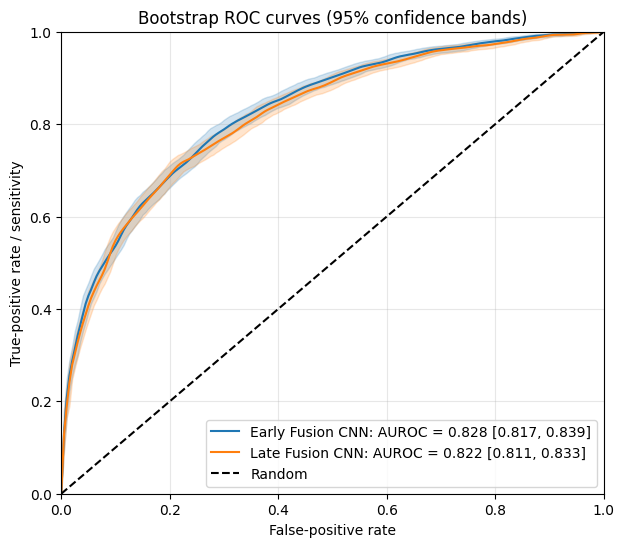

In [21]:
plt.figure(figsize=(7, 6))

for name, result, color in [
    ("Early Fusion CNN", early_boot, "C0"),
    ("Late Fusion CNN", late_boot, "C1"),
]:
    plt.plot(
        result["fpr_grid"],
        result["roc_tpr_mean"],
        color=color,
        label=(
            f"{name}: AUROC = {result['AUROC_mean']:.3f} "
            f"[{result['AUROC_lower']:.3f}, {result['AUROC_upper']:.3f}]"
        ),
    )
    plt.fill_between(
        result["fpr_grid"],
        result["roc_tpr_lower"],
        result["roc_tpr_upper"],
        color=color,
        alpha=0.20,
    )

plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate / sensitivity")
plt.title("Bootstrap ROC curves (95% confidence bands)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

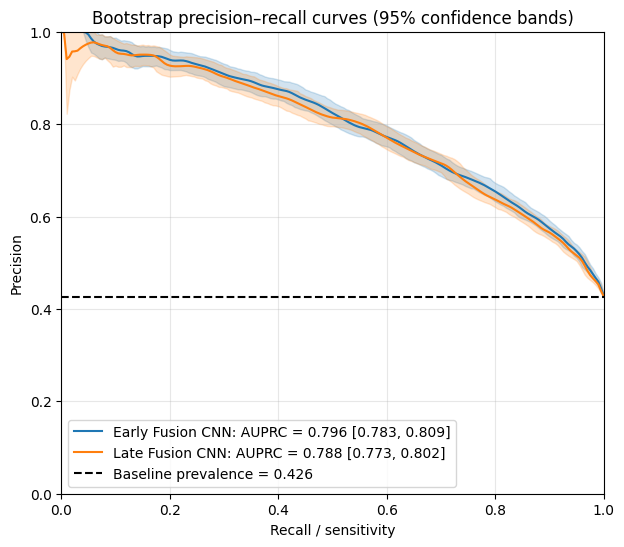

In [22]:
plt.figure(figsize=(7, 6))

for name, result, color in [
    ("Early Fusion CNN", early_boot, "C0"),
    ("Late Fusion CNN", late_boot, "C1"),
]:
    plt.plot(
        result["recall_grid"],
        result["pr_precision_mean"],
        color=color,
        label=(
            f"{name}: AUPRC = {result['AUPRC_mean']:.3f} "
            f"[{result['AUPRC_lower']:.3f}, {result['AUPRC_upper']:.3f}]"
        ),
    )
    plt.fill_between(
        result["recall_grid"],
        result["pr_precision_lower"],
        result["pr_precision_upper"],
        color=color,
        alpha=0.20,
    )

plt.axhline(
    early_boot["prevalence"],
    color="black",
    linestyle="--",
    label=f"Baseline prevalence = {early_boot['prevalence']:.3f}",
)
plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")
plt.title("Bootstrap precision–recall curves (95% confidence bands)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [23]:
def bootstrap_binary_classification_metrics(
    y_true,
    probs,
    n_bootstrap=1000,
    n_bins=10,
    ci=0.95,
    seed=42,
):
    """
    Bootstrap confidence intervals for all scalar metrics returned by
    calculate_binary_classification_metrics().

    Returns
    -------
    bootstrap_draws : pd.DataFrame
        One row per bootstrap sample and one column per metric.
    summary : pd.DataFrame
        Bootstrap mean, median, SD, and central confidence interval per metric.
    """
    y_true = np.asarray(y_true).astype(int).ravel()
    probs = np.asarray(probs, dtype=float).ravel()

    if len(y_true) != len(probs):
        raise ValueError("y_true and probs must have the same length.")

    if set(np.unique(y_true)) != {0, 1}:
        raise ValueError("y_true must contain both classes: 0 and 1.")

    rng = np.random.default_rng(seed)
    alpha = (1 - ci) / 2

    positive_idx = np.where(y_true == 1)[0]
    negative_idx = np.where(y_true == 0)[0]

    bootstrap_metrics = []

    for bootstrap_idx in range(n_bootstrap):
        # Stratified resampling preserves the observed class prevalence.
        sampled_idx = np.concatenate([
            rng.choice(positive_idx, size=len(positive_idx), replace=True),
            rng.choice(negative_idx, size=len(negative_idx), replace=True),
        ])
        rng.shuffle(sampled_idx)

        y_boot = y_true[sampled_idx]
        p_boot = probs[sampled_idx]

        metric_dict = calculate_binary_classification_metrics(
            y_true=y_boot,
            probs=p_boot,
            n_bins=n_bins,
        )

        # Assumes the function returns a dictionary of scalar metric values.
        metric_dict["bootstrap_draw"] = bootstrap_idx
        bootstrap_metrics.append(metric_dict)

    bootstrap_draws = (
        pd.DataFrame(bootstrap_metrics)
        .set_index("bootstrap_draw")
    )

    summary = pd.DataFrame({
        "bootstrap_mean": bootstrap_draws.mean(),
        "bootstrap_median": bootstrap_draws.median(),
        "bootstrap_sd": bootstrap_draws.std(ddof=1),
        f"lower_{int(100 * alpha)}": bootstrap_draws.quantile(alpha),
        f"upper_{int(100 * (1 - alpha))}": bootstrap_draws.quantile(1 - alpha),
    })

    return bootstrap_draws, summary

In [24]:
y_true = as_numpy(ytest1).astype(int)

early_bootstrap_draws, early_bootstrap_summary = (
    bootstrap_binary_classification_metrics(
        y_true=y_true,
        probs=p3,
        n_bootstrap=1000,
        n_bins=10,
        seed=1,
    )
)

late_bootstrap_draws, late_bootstrap_summary = (
    bootstrap_binary_classification_metrics(
        y_true=y_true,
        probs=p4,
        n_bootstrap=1000,
        n_bins=10,
        seed=2,
    )
)

display(early_bootstrap_summary)
display(late_bootstrap_summary)

,bootstrap_mean,bootstrap_median,bootstrap_sd,lower_2,upper_97
accuracy,0.744351,0.744395,5.274056e-03,0.734105,0.755053
balanced_accuracy,0.716400,0.716322,5.740581e-03,0.705407,0.727934
auroc,0.828478,0.828627,5.567386e-03,0.817445,0.839155
auprc,0.796171,0.796442,6.884728e-03,0.782515,0.809180
sensitivity,0.527680,0.527610,1.030862e-02,0.507334,0.548318
specificity,0.905120,0.905250,5.187849e-03,0.895006,0.915493
negative_log_likelihood,0.513614,0.513627,7.019237e-03,0.500144,0.528141
brier_score,0.170855,0.170890,2.712968e-03,0.165618,0.176281
expected_calibration_error,0.034779,0.034619,5.057740e-03,0.024408,0.044526
tn,2827.595000,2828.000000,1.620684e+01,2796.000000,2860.000000


,bootstrap_mean,bootstrap_median,bootstrap_sd,lower_2,upper_97
accuracy,0.753922,0.753951,5.753560e-03,0.742737,0.765344
balanced_accuracy,0.740420,0.740297,6.031494e-03,0.728679,0.752019
auroc,0.821806,0.821709,5.601911e-03,0.811154,0.833323
auprc,0.787868,0.787653,7.321623e-03,0.773450,0.802177
sensitivity,0.649253,0.649267,1.009521e-02,0.629853,0.669974
specificity,0.831587,0.831466,6.817631e-03,0.817862,0.844438
negative_log_likelihood,0.537989,0.538001,3.987468e-03,0.529768,0.545611
brier_score,0.177929,0.177925,1.820937e-03,0.174205,0.181330
expected_calibration_error,0.089608,0.089485,5.463552e-03,0.079338,0.100087
tn,2597.878000,2597.500000,2.129828e+01,2555.000000,2638.025000
